# Day 8 · Feature detection (Harris, SIFT, ORB) + mini project: panorama stitching

**Course lab:** `CV-Week2-Lecture1.ipynb` (Day 8)
**Notes chapter:** `week-2/notes/01_feature_detection_harris_sift_orb.md` (read it for the full theory)

**What you will learn**
1. What a "feature" (keypoint) is and why corners make good ones.
2. How to run the three detectors from the lab (**Harris**, **SIFT**, **ORB**) and what *every* parameter means.
3. The lab exercise done properly: number of keypoints, speed, and *where* they land on several images.
4. A measured experiment that **proves** (or questions) the textbook claims "Harris is not scale/rotation invariant, SIFT is, ORB is rotation invariant but weaker on scale".
5. The mini project: **panorama stitching**. The course code has a real bug (the left image is thrown away); we show the bug with real photos and fix it.

**Run time:** about 20–30 seconds on a laptop CPU (it downloads ~3 MB of images the first time).
Everything below was executed; all numbers in the text come from the outputs you see.

## 1 · Theory recap in plain language

**A feature (keypoint)** is a small spot in an image that you could find again in another photo of the same scene. Think of giving directions: "turn left at the *church tower*" works; "turn left at the *blue sky*" doesn't. Good features are **distinctive** (unlike their neighbours) and **repeatable** (found again after the camera moves, zooms or rotates).

| Region type | What happens if you slide a small window over it | Good landmark? |
|---|---|---|
| Flat area (sky, wall) | nothing changes in any direction | ❌ |
| Edge (horizon, door frame) | changes across the edge, **not along it** | ❌ you can't tell *where* along the edge you are |
| **Corner** | changes in **every** direction | ✅ unique and easy to pin down |

**Detector vs descriptor** (examiners love this distinction):
- a **detector** answers *where* are the interesting points? (x, y, and for SIFT/ORB also size and angle)
- a **descriptor** answers *what does the neighbourhood look like?* as a vector of numbers, so points can be **compared** between images.

### Harris (1988): "does the window change in every direction?"
For every pixel, Harris looks at the image gradients (how fast brightness changes in x and y) inside a small window and builds a 2×2 matrix **M** (the *structure tensor*). Its two eigenvalues λ1, λ2 say how much the brightness changes in the two main directions:
- both small → flat; one big, one small → edge; **both big → corner**.

To avoid computing eigenvalues, Harris uses a score **R = det(M) − k·trace(M)² = λ1·λ2 − k(λ1+λ2)²**. R is large and positive at corners, negative at edges, near 0 on flat areas. Harris gives **only a location and a score, no descriptor and no scale**.

### SIFT (Lowe, 2004): "find blobs at every zoom level"
1. **Scale space:** blur the image more and more (Gaussian) and also shrink it (an image *pyramid*).
2. **Difference of Gaussians (DoG):** subtract neighbouring blur levels; keep points that are a maximum/minimum compared with their 26 neighbours in space *and* scale. This gives each keypoint its own **size** → scale invariance.
3. **Orientation:** the dominant gradient direction around the point → rotation invariance.
4. **Descriptor:** a 4×4 grid of 8-bin gradient histograms = **128 numbers** (float).

### ORB (Rublee et al., 2011): "fast and free"
**O**riented **F**AST and **R**otated **B**RIEF:
- **FAST** finds corners very quickly (is a ring of 16 pixels much brighter/darker than the centre?), ranked with the Harris score, on an **8-level pyramid** (scale factor 1.2) to cope with some zoom;
- an **orientation** from the intensity centroid (rotation invariance);
- **BRIEF** descriptor: 256 yes/no brightness comparisons → **32 bytes, binary**, compared with the **Hamming distance** (count of differing bits), which is very fast.

## 2 · Setup

The course notebook used `Ganesh3.jpg`, `blackdog.jpg`, `left.jpg` and `right.jpg`, but **those files were never given to students**, so the original cells crash with `None` errors (or "Image not found"). We download free, public OpenCV sample images instead. If you do have the course images, just change the file names.

| Course file (missing) | Replacement used here | Why |
|---|---|---|
| `Ganesh3.jpg` (Harris) | `building.jpg` (OpenCV samples) | a building facade full of real corners |
| `blackdog.jpg` (SIFT/ORB) | `messi5.jpg` (OpenCV samples) | a natural photo (person, grass, crowd) |
| `left.jpg`, `right.jpg` (panorama) | `s1.jpg`, `s2.jpg` (OpenCV stitching test data) | a genuine left/right pair of the Pont du Gard |

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = ["jpeg"]
import time
import numpy as np
import matplotlib.pyplot as plt
import cv2

plt.rcParams["figure.dpi"] = 80          # small JPEG figures keep the saved notebook small
print("OpenCV version:", cv2.__version__)   # SIFT_create needs OpenCV >= 4.4

import os, urllib.request

DATA, OUT = "data", "output"            # data/ and output/ sit next to this notebook (both are git-ignored)
os.makedirs(DATA, exist_ok=True)
os.makedirs(OUT, exist_ok=True)

OPENCV_SAMPLES = "https://raw.githubusercontent.com/opencv/opencv/4.x/samples/data/"
OPENCV_STITCH  = "https://raw.githubusercontent.com/opencv/opencv_extra/4.x/testdata/stitching/"

def download(url, path):
    """Download url to path once; later runs reuse the cached file."""
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return path
    print("downloading", url)
    tmp = path + ".part"
    try:
        urllib.request.urlretrieve(url, tmp)
        os.replace(tmp, path)
    except Exception as e:
        raise RuntimeError(
            f"Could not download {url}\n({e})\n"
            f"Are you offline? Open the URL in a browser, save the file as\n  {os.path.abspath(path)}\n"
            "and re-run this cell. (Or use any image/video of your own and change the file name.)") from e
    return path

def to_rgb(img):
    """OpenCV stores colour as B,G,R; matplotlib expects R,G,B. Grey images are left alone."""
    return img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def show(images, titles=None, cols=None, size=4.5, max_side=900):
    """Show one or more OpenCV images side by side (downscaled for a small notebook file)."""
    if not isinstance(images, (list, tuple)):
        images, titles = [images], [titles]
    cols = cols or len(images)
    rows = (len(images) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(size * cols, size * rows * 0.75), squeeze=False)
    for ax in axes.ravel():
        ax.axis("off")
    for i, img in enumerate(images):
        s = min(1.0, max_side / max(img.shape[:2]))
        if s < 1:
            img = cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
        ax = axes.ravel()[i]
        ax.imshow(to_rgb(img), cmap="gray" if img.ndim == 2 else None)
        if titles and titles[i]:
            ax.set_title(titles[i], fontsize=10)
    plt.tight_layout()
    plt.show()

files = {
    "building.jpg": OPENCV_SAMPLES + "building.jpg",
    "messi5.jpg":   OPENCV_SAMPLES + "messi5.jpg",
    "graf1.png":    OPENCV_SAMPLES + "graf1.png",
    "blox.jpg":     OPENCV_SAMPLES + "blox.jpg",
    "s1.jpg":       OPENCV_STITCH + "s1.jpg",
    "s2.jpg":       OPENCV_STITCH + "s2.jpg",
    "boat1.jpg":    OPENCV_STITCH + "boat1.jpg",
    "boat2.jpg":    OPENCV_STITCH + "boat2.jpg",
}
for name, url in files.items():
    download(url, os.path.join(DATA, name))
print(sorted(os.listdir(DATA)))

OpenCV version: 5.0.0
['blox.jpg', 'boat1.jpg', 'boat2.jpg', 'building.jpg', 'graf1.png', 'messi5.jpg', 's1.jpg', 's2.jpg']


## 3 · Harris corners: the course code, explained line by line

Same calls and parameters as the course (`cv2.cornerHarris(gray, 2, 3, 0.04)` and the `0.01 * dst.max()` threshold); only the file name changed.

image size: (600, 868, 3) | dst (R map) shape: (600, 868) float32
R ranges from -4.13e+07 (edges, negative) to 2.98e+07 (strongest corner)
red pixels: 6548


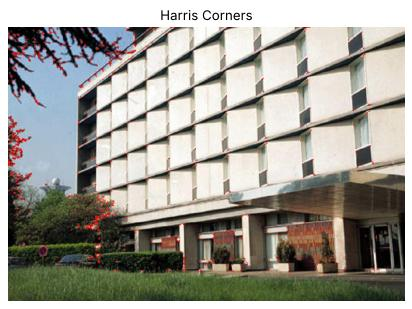

In [2]:
img = cv2.imread(os.path.join(DATA, 'building.jpg'))      # course: 'Ganesh3.jpg' (not provided)
if img is None:                                            # imread does NOT raise an error, it silently returns None
    raise FileNotFoundError("Image not found: check the path")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)               # Harris works on one brightness channel

gray = np.float32(gray)                                    # cornerHarris wants float32 input
dst = cv2.cornerHarris(gray, 2, 3, 0.04)                   # blockSize=2, ksize=3, k=0.04 -> R score for EVERY pixel
img_harris = img.copy()
img_harris[dst > 0.01 * dst.max()] = [0, 0, 255]           # paint pixels with R > 1% of the best score red (BGR!)

print("image size:", img.shape, "| dst (R map) shape:", dst.shape, dst.dtype)
print(f"R ranges from {dst.min():.3g} (edges, negative) to {dst.max():.3g} (strongest corner)")
print("red pixels:", int((dst > 0.01 * dst.max()).sum()))

plt.imshow(cv2.cvtColor(img_harris, cv2.COLOR_BGR2RGB))   # BGR -> RGB so red looks red
plt.title("Harris Corners")
plt.axis('off')
plt.show()

### What each Harris parameter means

| Parameter | Course value | Meaning | Bigger value → |
|---|---|---|---|
| `blockSize` | 2 | size of the neighbourhood (window) used to build the matrix M | smoother response, finds larger corners, fewer tiny ones |
| `ksize` | 3 | size of the **Sobel** filter used to compute the gradients (odd: 1, 3, 5, 7) | gradients less noisy but blurrier |
| `k` | 0.04 | the "k" in R = det − k·trace² (typical 0.04–0.06) | **fewer** corners (edges are penalised more) |
| `0.01 * dst.max()` | 1 % | not a Harris parameter: *our* threshold, relative to the strongest corner | fewer red pixels |

Two things that the course output hides:
1. **Red pixels are not corners.** One physical corner usually produces a small *blob* of several pixels above the threshold. To count corners we group touching red pixels (connected components) or use non-maximum suppression.
2. The threshold is **relative** (1 % of the maximum), so one very strong corner can suppress everything else, and the count changes from image to image.

Let's measure the effect of each parameter (the count is the number of corner *blobs*).

setting                          red pixels   corners (blobs)
course: block=2, ksize=3, k=0.04, 1%       6548       1152
rel=0.001                             21262       2601
rel=0.1                                 682        296


k=0.06                                 4924       1086
block=5                               27229        608
ksize=7                                7478       1063


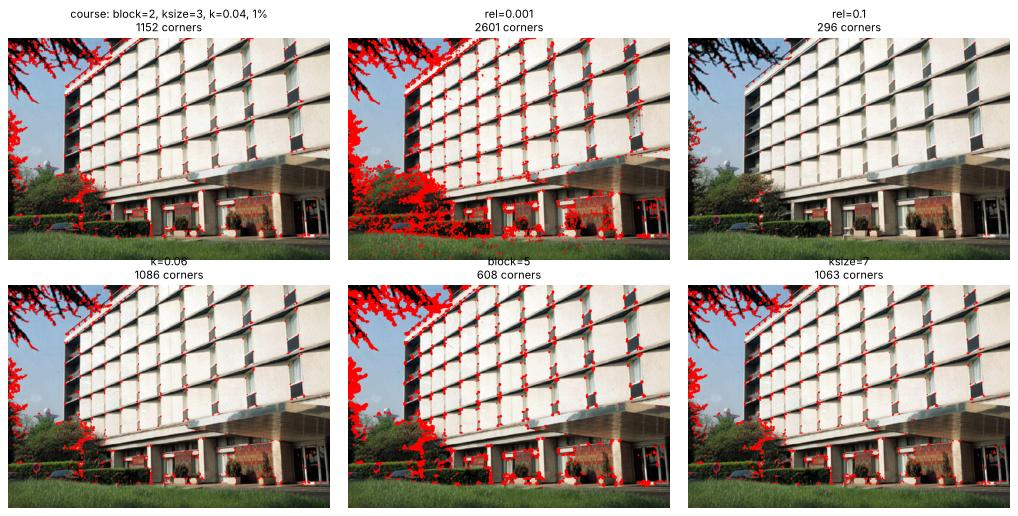

In [3]:
def harris_count(gray, block=2, ksize=3, k=0.04, rel=0.01):
    R = cv2.cornerHarris(np.float32(gray), block, ksize, k)
    mask = (R > rel * R.max()).astype(np.uint8)
    n_blobs = cv2.connectedComponents(mask)[0] - 1          # label 0 is the background
    return R, mask, n_blobs

g = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
settings = [dict(), dict(rel=0.001), dict(rel=0.1), dict(k=0.06), dict(block=5), dict(ksize=7)]
panels, titles = [], []
print(f"{'setting':32s} red pixels   corners (blobs)")
for s in settings:
    R, mask, n = harris_count(g, **s)
    label = ", ".join(f"{a}={b}" for a, b in s.items()) or "course: block=2, ksize=3, k=0.04, 1%"
    print(f"{label:32s} {int(mask.sum()):10d}   {n:8d}")
    vis = img.copy()
    vis[cv2.dilate(mask, None) > 0] = (0, 0, 255)            # dilate = make the dots bigger so you can see them
    panels.append(vis); titles.append(f"{label}\n{n} corners")
show(panels, titles, cols=3, size=4.3)

**Reading the table:** lowering the threshold to 0.1 % floods the image with weak corners (texture, noise); raising it to 10 % keeps only the very strongest. Increasing `k` removes edge-like responses. A larger `blockSize` merges nearby corners into fewer, larger blobs. A larger `ksize` (Sobel 7) changes the gradient scale and therefore which corners win.

## 4 · SIFT keypoints: the course code

Same code as the course (`cv2.SIFT_create()`, `detectAndCompute`, rich keypoints). `cv2.SIFT_create` is in the main OpenCV package since version 4.4 (the patent expired in March 2020). Older versions needed `cv2.xfeatures2d.SIFT_create()` from `opencv-contrib-python`.

SIFT keypoints: 640 | descriptor array: (640, 128) float32
largest keypoint: pt=(96.3, 151.4) size=49.1px angle=78.8 deg octave=3


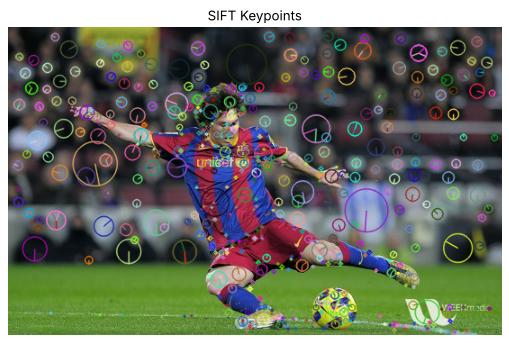

In [4]:
# Load the image
img = cv2.imread(os.path.join(DATA, 'messi5.jpg'))   # course: 'blackdog.jpg' (not provided)
if img is None:
    raise ValueError("Image not found. Check the file path.")

# Convert to grayscale (uint8)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Create SIFT detector (default: keep all keypoints, 3 layers per octave, contrastThreshold 0.04, edgeThreshold 10, sigma 1.6)
sift = cv2.SIFT_create()

# Detect keypoints and compute their 128-number descriptors in one call; None = no mask (search the whole image)
kp, des = sift.detectAndCompute(gray, None)

# Draw keypoints: RICH = circle radius shows the keypoint's scale, the line shows its orientation
img_sift = cv2.drawKeypoints(img, kp, None,
                             flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

print("SIFT keypoints:", len(kp), "| descriptor array:", des.shape, des.dtype)
k0 = max(kp, key=lambda k: k.size)
print(f"largest keypoint: pt=({k0.pt[0]:.1f}, {k0.pt[1]:.1f}) size={k0.size:.1f}px angle={k0.angle:.1f} deg octave={k0.octave & 255}")

plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(img_sift, cv2.COLOR_BGR2RGB))
plt.title("SIFT Keypoints")
plt.axis('off')
plt.show()

**What a keypoint object holds:** `kp[i].pt` (x, y), `.size` (diameter of the meaningful neighbourhood → the circle), `.angle` (orientation in degrees → the line), `.response` (strength), `.octave` (pyramid level). `des` has **one row of 128 float32 numbers per keypoint**.

Useful `SIFT_create` parameters: `nfeatures` (keep only the N best; 0 = all), `contrastThreshold` (higher → fewer, stronger keypoints in low-contrast regions), `edgeThreshold` (higher → keeps more edge-like points), `sigma` (blur of the first level).

## 5 · ORB keypoints: the course code

ORB keypoints: 500 | descriptor array: (500, 32) uint8 = 32 bytes = 256 bits each


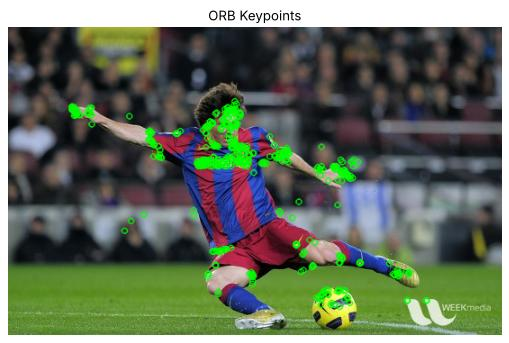

In [5]:
orb = cv2.ORB_create()                                    # defaults: nfeatures=500, scaleFactor=1.2, nlevels=8, fastThreshold=20
kp_orb, des_orb = orb.detectAndCompute(gray, None)        # same grey image as the SIFT cell
img_orb = cv2.drawKeypoints(img, kp_orb, None, color=(0,255,0), flags=0)   # flags=0: just small circles, no size/angle

print("ORB keypoints:", len(kp_orb), "| descriptor array:", des_orb.shape, des_orb.dtype, "= 32 bytes = 256 bits each")

plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(img_orb, cv2.COLOR_BGR2RGB))
plt.title("ORB Keypoints")
plt.axis('off')
plt.show()

**Why exactly 500?** `ORB_create()` has `nfeatures=500` by default: ORB finds many FAST corners and then keeps the 500 with the best Harris score. That is a cap, not a property of the image; ask for more with `cv2.ORB_create(nfeatures=2000)`.

Other ORB parameters worth knowing: `scaleFactor=1.2` and `nlevels=8` (the pyramid: 8 levels, each 1.2× smaller, so it covers about a 1.2⁷ ≈ 3.6× zoom range), `edgeThreshold=31` (border where no features are detected, because the descriptor patch needs room), `fastThreshold=20` (how much brighter/darker the ring must be), `WTA_K=2` (pixels compared per BRIEF test; 3 or 4 need `NORM_HAMMING2`).

Note how ORB keypoints **cluster** on high-contrast textured regions (the crowd, the advertising boards), whereas SIFT spreads more evenly. ORB keeps the 500 strongest FAST corners, and they bunch together where the contrast is highest.

## 6 · Exercise: detect keypoints in different images, compare number, speed and distribution

The course exercise asks us to run all three detectors on different images (building facades, natural scenes) and compare. We do it on four images, time each detector (median of 3 runs, detection + description) and count:
- Harris: corner blobs with the course settings;
- SIFT: default settings (no cap);
- ORB: default (cap 500) **and** `nfeatures=5000` so the comparison is fair.

image              size | Harris     ms |  SIFT     ms | ORB500    ms | ORB5000    ms
building.jpg    868x600 |   1152    5.7 |  4566  276.2 |    500   9.4 |    5000  17.9
messi5.jpg      548x342 |    218    1.5 |   640   34.6 |    500   3.8 |    2573   7.0
graf1.png       800x640 |    824    4.1 |  2674  156.5 |    500   8.6 |    5000  16.1
blox.jpg        256x256 |     65    0.5 |   187    9.9 |    290   1.5 |     290   1.5


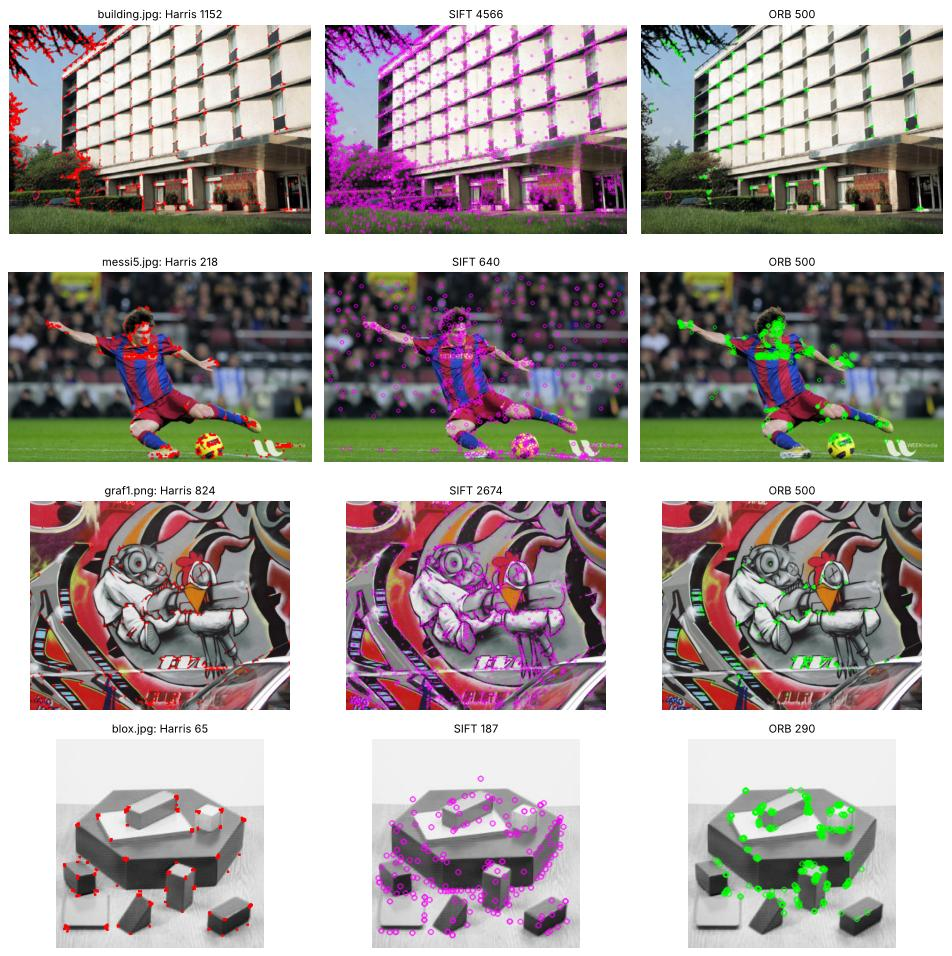

In [6]:
def timed(fn, reps=3):
    ts = []
    for _ in range(reps):
        t = time.perf_counter(); out = fn(); ts.append(time.perf_counter() - t)
    return out, 1000 * np.median(ts)

names = ["building.jpg", "messi5.jpg", "graf1.png", "blox.jpg"]
sift, orb500, orb5k = cv2.SIFT_create(), cv2.ORB_create(), cv2.ORB_create(nfeatures=5000)
rows, panels, titles = [], [], []
for name in names:
    im = cv2.imread(os.path.join(DATA, name))
    g = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
    (R, mask, nh), th = timed(lambda: harris_count(g))
    (ks, _), ts = timed(lambda: sift.detectAndCompute(g, None))
    (ko, _), to = timed(lambda: orb500.detectAndCompute(g, None))
    (ko5, _), to5 = timed(lambda: orb5k.detectAndCompute(g, None))
    rows.append((name, f"{g.shape[1]}x{g.shape[0]}", nh, th, len(ks), ts, len(ko), to, len(ko5), to5))
    vis_h = im.copy(); vis_h[cv2.dilate(mask, None) > 0] = (0, 0, 255)
    panels += [vis_h,
               cv2.drawKeypoints(im, ks, None, color=(255, 0, 255)),
               cv2.drawKeypoints(im, ko, None, color=(0, 255, 0))]
    titles += [f"{name}: Harris {nh}", f"SIFT {len(ks)}", f"ORB {len(ko)}"]

print(f"{'image':13s} {'size':>9s} | {'Harris':>6s} {'ms':>6s} | {'SIFT':>5s} {'ms':>6s} | {'ORB500':>6s} {'ms':>5s} | {'ORB5000':>7s} {'ms':>5s}")
for r in rows:
    print(f"{r[0]:13s} {r[1]:>9s} | {r[2]:6d} {r[3]:6.1f} | {r[4]:5d} {r[5]:6.1f} | {r[6]:6d} {r[7]:5.1f} | {r[8]:7d} {r[9]:5.1f}")
show(panels, titles, cols=3, size=4.0, max_side=500)

**What the measurements show (this machine; your times will differ):**

- **Speed.** Harris is by far the fastest (about 0.5–4 ms per image) because it is a single filtering pass, but it only gives *locations*: no descriptor, no scale, no angle. ORB (500 points) takes about 1.5–10 ms. SIFT is the slowest: about 135 ms on `building.jpg`, roughly **14× slower than ORB-500** and still about **8× slower than ORB asked for 5000 points**.
- **Count.** The lab's "learning point" says *SIFT finds fewer keypoints*. With default settings we saw the opposite on every image: SIFT found 4566 on `building.jpg` vs ORB's 500. The reason is simply that `ORB_create()` **stops at 500** (`nfeatures`), while `SIFT_create()` keeps everything above its contrast threshold. Asked for 5000, ORB returned 5000 on the two big images, but only 2573 on `messi5.jpg`. "Fewer/more" is a setting, not a property of the method.
- `blox.jpg` (a small 256×256 synthetic scene) shows the limits: ORB found only 290 because it ignores a 31-pixel border (`edgeThreshold`) and the smooth surfaces have few FAST corners. Harris found 65 corner blobs, almost all on the real block corners.
- **Distribution (look at the grid).** Harris marks building corners but also floods the fine tree branches (texture looks "cornery"). SIFT spreads over the whole image at many sizes, including blobs in foliage, grass and the crowd. ORB's 500 points **bunch together** on the highest-contrast spots (window corners, the player's shirt) and leave large areas empty. This matters for stitching and tracking, where you want points everywhere.

## 7 · Experiment: are they really scale and rotation invariant? Let's *prove* it

The lecture claims: *Harris is not scale/rotation invariant; SIFT is scale **and** rotation invariant; ORB is rotation invariant but weaker on scale.* Instead of believing it, we test it.

**Method.** Take an image, rotate or rescale it by a **known** amount, so we know exactly where every original pixel must land (ground truth). Then measure two things:

1. **Repeatability of the detector:** of the keypoints found in the original, what % are found again (within 2.5 px, at the coarser resolution) at the predicted place in the transformed image? We also report the **chance level**: the same score for random points, so we know what "luck" looks like.
2. **Correct matches (detector + descriptor):** match descriptors between the two images (brute force, cross-check) and count what % of the matches land at the right place. Harris has no descriptor, so we give it the simplest one: the raw 11×11 pixel patch around the corner (normalised for brightness). This is what "using Harris for matching" means in practice.

All detectors are limited to their **500 best** points so that no detector wins just by having more points.

In [7]:
N = 500
sift_n, orb_n = cv2.SIFT_create(nfeatures=N), cv2.ORB_create(nfeatures=N)

def harris_with_patch(g):
    """Harris corners (500 best, course's k=0.04, blockSize=2) + an 11x11 raw-pixel patch as a naive descriptor."""
    p = cv2.goodFeaturesToTrack(g, N, 0.01, 5, blockSize=2, useHarrisDetector=True, k=0.04)
    p = np.zeros((0, 2), np.float32) if p is None else p.reshape(-1, 2)
    gp = cv2.copyMakeBorder(g, 8, 8, 8, 8, cv2.BORDER_REFLECT).astype(np.float32)
    d = []
    for x, y in p:
        x, y = int(round(x)) + 8, int(round(y)) + 8
        patch = gp[y-5:y+6, x-5:x+6].ravel()
        d.append((patch - patch.mean()) / (patch.std() + 1e-6))
    return p, np.float32(d)

def with_desc(det):
    def f(g):
        k, d = det.detectAndCompute(g, None)
        return np.float32([q.pt for q in k]), d
    return f

DETECTORS = {"Harris": (harris_with_patch, cv2.NORM_L2),
             "SIFT":   (with_desc(sift_n), cv2.NORM_L2),
             "ORB":    (with_desc(orb_n), cv2.NORM_HAMMING)}

def transform(g, angle=0, scale=1.0):
    """Rotate/scale about the centre on a canvas big enough to keep the whole image. Returns image and the 2x3 matrix."""
    h, w = g.shape
    M = cv2.getRotationMatrix2D((w / 2, h / 2), angle, scale)
    c, s = abs(M[0, 0]), abs(M[0, 1])
    nw, nh = int(w * c + h * s), int(h * c + w * s)
    M[0, 2] += nw / 2 - w / 2; M[1, 2] += nh / 2 - h / 2
    return cv2.warpAffine(g, M, (nw, nh)), M

rng = np.random.default_rng(0)
def evaluate(g, name, angle=0, scale=1.0):
    f, norm = DETECTORS[name]
    p, dp = f(g)
    g2, M = transform(g, angle, scale)
    q, dq = f(g2)
    p_true = p @ M[:, :2].T + M[:, 2]                 # where each original keypoint MUST be in the new image
    eps = 2.5 * max(1.0, scale)                       # 2.5 px at the coarser of the two resolutions
    dist = np.linalg.norm(p_true[:, None] - q[None], axis=2)
    repeat = 100 * (dist.min(1) < eps).mean()
    q_rand = np.c_[rng.uniform(0, g2.shape[1], len(q)), rng.uniform(0, g2.shape[0], len(q))]
    chance = 100 * (np.linalg.norm(p_true[:, None] - q_rand[None], axis=2).min(1) < eps).mean()
    matches = cv2.BFMatcher(norm, crossCheck=True).match(dp, dq)
    ok = [np.linalg.norm(p_true[m.queryIdx] - q[m.trainIdx]) < eps for m in matches]
    return repeat, chance, 100 * np.mean(ok) if ok else 0.0, int(np.sum(ok))

In [8]:
angles, scales = [0, 15, 30, 45, 90, 180], [0.5, 0.75, 1.0, 1.5, 2.0, 3.0]
results = {}
for im_name in ["building.jpg", "graf1.png"]:
    g = cv2.imread(os.path.join(DATA, im_name), cv2.IMREAD_GRAYSCALE)
    s = 640 / max(g.shape); g = cv2.resize(g, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)
    for det in DETECTORS:
        results[(im_name, det, "rot")] = [evaluate(g, det, angle=a) for a in angles]
        results[(im_name, det, "scale")] = [evaluate(g, det, scale=sc) for sc in scales]

for kind, xs, unit in [("rot", angles, "deg"), ("scale", scales, "x")]:
    print(f"\n=== {'ROTATION' if kind == 'rot' else 'SCALE'}: repeatability% (chance%) | correct matches% ===")
    for im_name in ["building.jpg", "graf1.png"]:
        print(im_name)
        print("  " + " " * 7 + "".join(f"{str(x) + unit:>18s}" for x in xs))
        for det in DETECTORS:
            cells = [f"{r:3.0f} ({c:2.0f}) | {m:3.0f}%" for r, c, m, _ in results[(im_name, det, kind)]]
            print(f"  {det:7s}" + "".join(f"{x:>18s}" for x in cells))


=== ROTATION: repeatability% (chance%) | correct matches% ===
building.jpg
                       0deg             15deg             30deg             45deg             90deg            180deg
  Harris    100 ( 4) | 100%    84 ( 1) |  67%    74 ( 1) |   3%    64 ( 1) |   1%    98 ( 3) |   0%    96 ( 3) |   2%
  SIFT      100 ( 5) | 100%    75 ( 2) |  92%    75 ( 1) |  92%    76 ( 3) |  92%    93 ( 4) |  99%    89 ( 3) |  97%
  ORB       100 ( 0) | 100%    81 ( 3) |  77%    81 ( 3) |  75%    79 ( 3) |  78%    92 ( 3) |  81%    86 ( 4) |  69%
graf1.png
                       0deg             15deg             30deg             45deg             90deg            180deg
  Harris    100 ( 2) | 100%    80 ( 3) |  57%    77 ( 1) |   1%    78 ( 1) |   0%    88 ( 3) |   0%    85 ( 3) |   0%
  SIFT      100 ( 6) | 100%    75 ( 3) |  96%    74 ( 3) |  97%    75 ( 1) |  96%    91 ( 3) |  99%    91 ( 3) |  99%
  ORB       100 ( 2) | 100%    77 ( 3) |  89%    78 ( 1) |  90%    78 ( 1) |  90%    92 

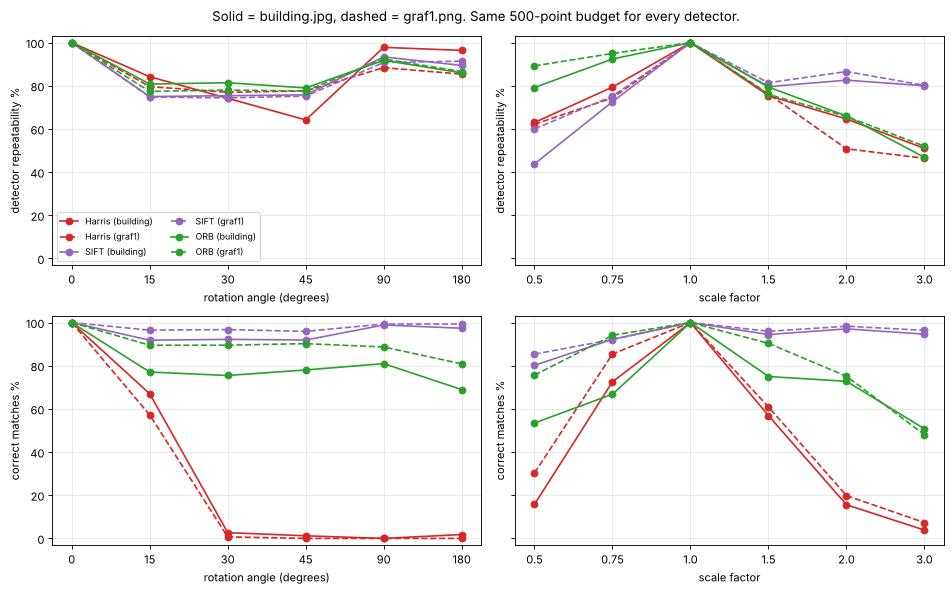

In [9]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), sharey=True)
colors = {"Harris": "tab:red", "SIFT": "tab:purple", "ORB": "tab:green"}
for col, (kind, xs, lab) in enumerate([("rot", angles, "rotation angle (degrees)"), ("scale", scales, "scale factor")]):
    for row, (idx, what) in enumerate([(0, "detector repeatability %"), (2, "correct matches %")]):
        ax = axes[row, col]
        for det in DETECTORS:
            for im_name, ls in [("building.jpg", "-"), ("graf1.png", "--")]:
                ys = [r[idx] for r in results[(im_name, det, kind)]]
                ax.plot(range(len(xs)), ys, ls, marker="o", color=colors[det],
                        label=f"{det} ({im_name.split('.')[0]})")
        ax.set_xticks(range(len(xs))); ax.set_xticklabels(xs); ax.set_xlabel(lab); ax.set_ylabel(what)
        ax.set_ylim(-3, 103); ax.grid(alpha=.3)
axes[0, 0].legend(fontsize=8, ncol=2)
fig.suptitle("Solid = building.jpg, dashed = graf1.png. Same 500-point budget for every detector.")
plt.tight_layout(); plt.show()

### What the experiment really shows (be ready to say this in the viva)


**Correct matches (bottom row: the result that matters for matching and stitching):**
- **Harris + raw patch collapses under rotation:** 57–67 % correct at 15°, then **≤ 3 % from 30° onwards** on both images. It also collapses under zoom: 4–7 % correct at 3×. A raw pixel patch has no idea the image turned or grew.
- **SIFT stays high everywhere:** 92–99 % correct at every rotation, and 80–98 % at every scale from 0.5× to 3×. This is the scale **and** rotation invariance the lecture promises.
- **ORB is rotation invariant** (69–90 % correct at all angles) but **weaker on scale:** it is fine from 0.75× to 1.5× (67–94 %) and drops to about **50 % at 3×** (51 % and 48 %). Its 8-level, 1.2× pyramid only covers about 3.6×, and each level is coarse.

**Detector repeatability (top row) has a surprise, and it is worth knowing for the viva:**
- **Harris *detection* is NOT badly hurt by rotation.** 64–98 % of Harris corners reappear at the right place after rotation, similar to SIFT and ORB (chance level 1–4 %). This is expected from the maths: R depends on the eigenvalues of M, and eigenvalues don't change when you rotate the image. The textbook phrase "Harris is not rotation invariant" is really about using Harris *for matching*: it gives no orientation, so the patch you compare is not rotated.
- **Scale is where Harris detection really fails:** when the image is enlarged 3×, only 46–51 % of the corners reappear (SIFT: 80 %), because a sharp corner at one zoom becomes a rounded curve at another, and the fixed 2×2 window sees a different structure.
- SIFT's detector repeatability is "only" 74–93 % under rotation, because we kept only its 500 best points and the ranking shuffles slightly after resampling. Its descriptor makes up for it (≥ 92 % correct matches).
- At 0.5× all detectors lose points (and the chance level rises to 6–12 %, because the image is smaller and the same number of points fills more of it), so compare the curves against chance, not against 100 %.

**One-line summary:** *Harris = rotation-stable detector, but not scale invariant, and has no descriptor → useless for matching under rotation or zoom. SIFT = robust to both. ORB = robust to rotation, moderate scale range, much faster.*

## 8 · Mini project: panorama stitching

**Workflow (from the lecture):** detect ORB features → match them → estimate a **homography** with RANSAC → warp one image onto the other → paste.

- A **homography** is a 3×3 matrix H that maps points of one image plane to another: `[x', y', 1]ᵀ ∝ H·[x, y, 1]ᵀ`. It is exact when the scene is (almost) flat **or** the camera only rotates about its centre, which is the situation for a panorama taken from one spot. It has 8 degrees of freedom, so it needs at least **4 point pairs**.
- **RANSAC** (RANdom SAmple Consensus): pick 4 random matches, compute H, count how many other matches agree with it (within the *reprojection threshold*, 5 px here) → these are **inliers**. Repeat many times; keep the H with the most inliers. Wrong matches (outliers) simply don't vote for the right answer.

### 8a · The course code, run on a real left/right pair
We run the course cell **unchanged** except for the file names: `img1` = left photo, `img2` = right photo.

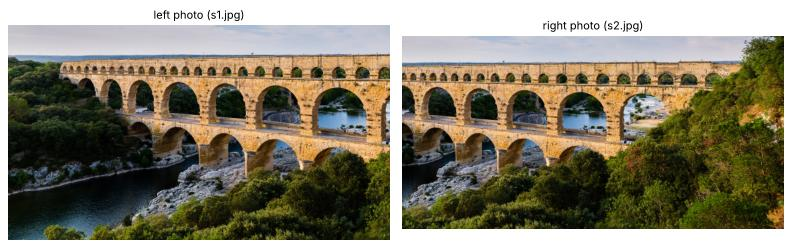

In [10]:
def load_small(name, scale=0.5):
    im = cv2.imread(os.path.join(DATA, name))
    if im is None:
        raise FileNotFoundError(name)
    return cv2.resize(im, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)

left_img, right_img = load_small("s1.jpg"), load_small("s2.jpg")     # same scale for both
show([left_img, right_img], ["left photo (s1.jpg)", "right photo (s2.jpg)"], size=5)

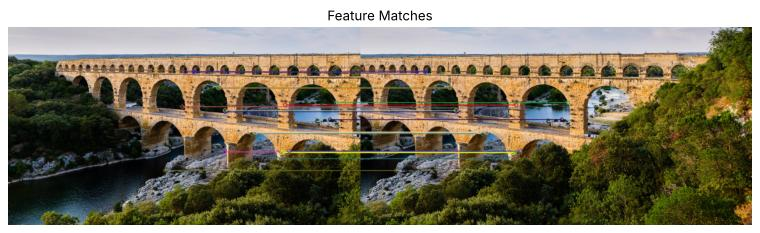

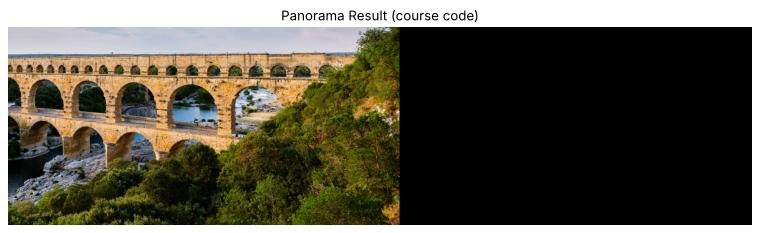

500 / 500 keypoints, 235 cross-checked matches, 206 RANSAC inliers (88%)


In [11]:
# ---- course code (only the file names changed) ----
img1 = left_img.copy()     # course: cv2.imread('left.jpg')
img2 = right_img.copy()    # course: cv2.imread('right.jpg')

# Convert to grayscale
gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

# Detect ORB keypoints and descriptors
orb = cv2.ORB_create()
kp1, des1 = orb.detectAndCompute(gray1, None)
kp2, des2 = orb.detectAndCompute(gray2, None)

# Match features: Hamming distance for binary ORB descriptors; crossCheck keeps i<->j only if each is the other's best match
bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)
matches = bf.match(des1, des2)
matches = sorted(matches, key=lambda x:x.distance)            # best (smallest distance) first

# Draw matches (flags=2 = NOT_DRAW_SINGLE_POINTS: don't draw unmatched keypoints)
img_matches = cv2.drawMatches(img1, kp1, img2, kp2, matches[:20], None, flags=2)
plt.figure(figsize=(12, 4))
plt.imshow(cv2.cvtColor(img_matches, cv2.COLOR_BGR2RGB))
plt.title("Feature Matches")
plt.axis('off')
plt.show()

# Estimate homography: maps points of img1 (left) INTO img2's (right) coordinate frame
src_pts = np.float32([ kp1[m.queryIdx].pt for m in matches ]).reshape(-1,1,2)
dst_pts = np.float32([ kp2[m.trainIdx].pt for m in matches ]).reshape(-1,1,2)
M, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC,5.0)

# Warp and stitch
h,w = img1.shape[:2]
result = cv2.warpPerspective(img1, M, (w + img2.shape[1], h))   # canvas starts at x=0 of img2's frame
result[0:img2.shape[0], 0:img2.shape[1]] = img2                 # paste img2 at the left of the canvas

plt.figure(figsize=(12, 4))
plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
plt.title("Panorama Result (course code)")
plt.axis('off')
plt.show()
print(f"{len(kp1)} / {len(kp2)} keypoints, {len(matches)} cross-checked matches, "
      f"{int(mask.sum())} RANSAC inliers ({100 * mask.mean():.0f}%)")

### 8b · Why is the left half of the panorama missing? Diagnosing the bug

The "panorama" above is just the **right photo followed by black**; the left photo has vanished. Let's ask the homography where the corners of `img1` (the left photo) end up:

In [12]:
corners1 = np.float32([[0, 0], [w, 0], [w, h], [0, h]]).reshape(-1, 1, 2)
where = cv2.perspectiveTransform(corners1, M).reshape(-1, 2)
for name, (x, y) in zip(["top-left", "top-right", "bottom-right", "bottom-left"], where):
    print(f"img1 {name:12s} -> x = {x:7.1f}, y = {y:6.1f}")
print(f"canvas covers x = 0 ... {w + img2.shape[1]}, img2 is pasted over x = 0 ... {img2.shape[1]}")

img1 top-left     -> x =  -214.8, y =    0.0
img1 top-right    -> x =   409.5, y =   -0.2
img1 bottom-right -> x =   407.6, y =  349.5
img1 bottom-left  -> x =  -214.4, y =  349.6
canvas covers x = 0 ... 1315, img2 is pasted over x = 0 ... 692


**The bug, in one sentence:** `M` maps the *left* image into the *right* image's frame, and in that frame the left image lies at **negative x** (to the left of the right photo). `warpPerspective` only draws pixels with x ≥ 0, so the whole strip from x ≈ −215 to 0 (a third of the left photo, including the river bank on the left) is simply lost. The part that does land at x ≥ 0 is the overlap, and it is then **overwritten** when `img2` is pasted at `[0:h, 0:w]`. Result: the left photo contributes nothing. (The course notebook's own saved output shows exactly this: its "Panorama Result" is the second image followed by a dark smear.)

The course code only works if `img1` is the **right** image and `img2` the **left** one: then H pushes `img1` to positive x, into the empty space on the right. That is why many online tutorials *seem* to work: they name the files the other way round.

**The fix (two parts):**
1. Compute the homography that maps the **right image into the left image's frame** (`findHomography(dst_pts, src_pts)`), warp the right image, and paste the left image at the origin.
2. More generally (any order, any direction): warp the corners first, compute the bounding box of *both* images, and add a **translation** so that nothing has negative coordinates. Then crop the black border.

We also improve the matches: instead of using *all* cross-checked matches (many are wrong; RANSAC copes, but only just), use the **Lowe ratio test** (Day 9) and report the inlier ratio.

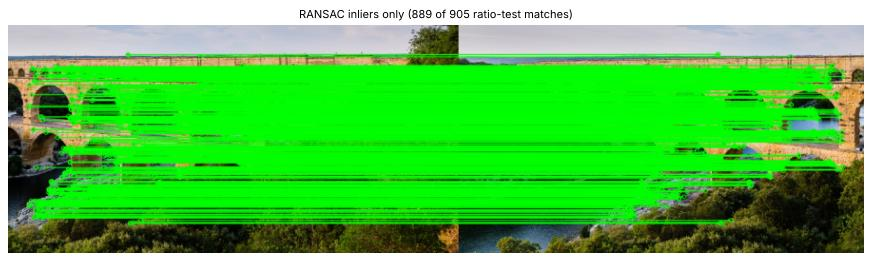

keypoints (1994, 2000), good matches after ratio test: 905, RANSAC inliers: 889 (98%)


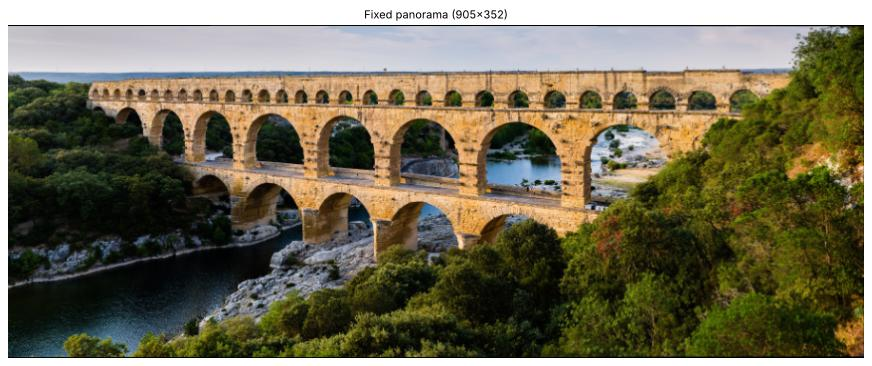

In [13]:
def stitch_pair(img_left, img_right, ratio=0.75, nfeatures=2000, show_matches=False):
    """Stitch two overlapping photos. Works whichever image is 'left': the canvas is translated to fit both."""
    g1 = cv2.cvtColor(img_left, cv2.COLOR_BGR2GRAY)
    g2 = cv2.cvtColor(img_right, cv2.COLOR_BGR2GRAY)
    orb = cv2.ORB_create(nfeatures=nfeatures)
    k1, d1 = orb.detectAndCompute(g1, None)
    k2, d2 = orb.detectAndCompute(g2, None)
    if d1 is None or d2 is None:
        raise RuntimeError("No features found in one of the images")

    # 1) match the RIGHT image to the LEFT image (query = right, train = left) and apply Lowe's ratio test
    knn = cv2.BFMatcher(cv2.NORM_HAMMING).knnMatch(d2, d1, k=2)
    good = [p[0] for p in knn if len(p) == 2 and p[0].distance < ratio * p[1].distance]
    if len(good) < 4:
        raise RuntimeError(f"Only {len(good)} good matches: need at least 4 for a homography")
    src = np.float32([k2[m.queryIdx].pt for m in good]).reshape(-1, 1, 2)   # points in the RIGHT image
    dst = np.float32([k1[m.trainIdx].pt for m in good]).reshape(-1, 1, 2)   # same points in the LEFT image
    H, inl = cv2.findHomography(src, dst, cv2.RANSAC, 5.0)                  # H: right -> left frame
    if H is None:
        raise RuntimeError("findHomography failed")

    # 2) bounding box of both images in the left image's frame, then shift so that nothing is negative
    h1, w1 = img_left.shape[:2]; h2, w2 = img_right.shape[:2]
    c2 = cv2.perspectiveTransform(np.float32([[0, 0], [w2, 0], [w2, h2], [0, h2]]).reshape(-1, 1, 2), H)
    allc = np.vstack([c2.reshape(-1, 2), [[0, 0], [w1, 0], [w1, h1], [0, h1]]])
    xmin, ymin = np.floor(allc.min(0)).astype(int); xmax, ymax = np.ceil(allc.max(0)).astype(int)
    T = np.array([[1, 0, -xmin], [0, 1, -ymin], [0, 0, 1]], dtype=np.float64)   # translation matrix
    pano = cv2.warpPerspective(img_right, T @ H, (xmax - xmin, ymax - ymin))
    pano[-ymin:-ymin + h1, -xmin:-xmin + w1] = img_left                          # paste the left image (shifted)

    # 3) crop the black border (rows/columns that are entirely empty)
    nz = np.argwhere(pano.max(axis=2) > 0)
    (y0, x0), (y1, x1) = nz.min(0), nz.max(0) + 1
    info = dict(kp=(len(k1), len(k2)), good=len(good), inliers=int(inl.sum()), inlier_ratio=float(inl.mean()), H=H)
    if show_matches:
        vis = cv2.drawMatches(img_right, k2, img_left, k1, [m for m, i in zip(good, inl.ravel()) if i], None,
                              matchColor=(0, 255, 0), flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
        show(vis, f"RANSAC inliers only ({info['inliers']} of {len(good)} ratio-test matches)", size=11)
    return pano[y0:y1, x0:x1], info

pano, info = stitch_pair(left_img, right_img, show_matches=True)
print(f"keypoints {info['kp']}, good matches after ratio test: {info['good']}, "
      f"RANSAC inliers: {info['inliers']} ({100 * info['inlier_ratio']:.0f}%)")
show(pano, f"Fixed panorama ({pano.shape[1]}x{pano.shape[0]})", size=11)

### 8c · How much does filtering the matches help? (inlier ratio)

RANSAC can find the right homography even when many matches are wrong, but the more outliers there are, the more random samples it needs and the more fragile it gets. We compare the **inlier ratio** (fraction of matches that agree with the final H) for the course's "all cross-checked matches" and for the ratio test.

In [14]:
g1, g2 = cv2.cvtColor(left_img, cv2.COLOR_BGR2GRAY), cv2.cvtColor(right_img, cv2.COLOR_BGR2GRAY)
for nf in [500, 2000]:
    orb = cv2.ORB_create(nfeatures=nf)
    k1, d1 = orb.detectAndCompute(g1, None); k2, d2 = orb.detectAndCompute(g2, None)
    cc = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True).match(d2, d1)
    knn = cv2.BFMatcher(cv2.NORM_HAMMING).knnMatch(d2, d1, k=2)
    for label, ms in [("cross-check (course)", cc)] + [
            (f"ratio test {r}", [p[0] for p in knn if len(p) == 2 and p[0].distance < r * p[1].distance]) for r in (0.7, 0.8)]:
        s = np.float32([k2[m.queryIdx].pt for m in ms]).reshape(-1, 1, 2)
        d = np.float32([k1[m.trainIdx].pt for m in ms]).reshape(-1, 1, 2)
        H, inl = cv2.findHomography(s, d, cv2.RANSAC, 5.0)
        print(f"nfeatures={nf:4d}  {label:22s} matches={len(ms):4d}  inliers={int(inl.sum()):4d}  inlier ratio={100 * inl.mean():5.1f}%")

nfeatures= 500  cross-check (course)   matches= 235  inliers= 206  inlier ratio= 87.7%
nfeatures= 500  ratio test 0.7         matches= 197  inliers= 194  inlier ratio= 98.5%
nfeatures= 500  ratio test 0.8         matches= 220  inliers= 205  inlier ratio= 93.2%


nfeatures=2000  cross-check (course)   matches=1026  inliers= 926  inlier ratio= 90.3%
nfeatures=2000  ratio test 0.7         matches= 874  inliers= 867  inlier ratio= 99.2%
nfeatures=2000  ratio test 0.8         matches= 944  inliers= 915  inlier ratio= 96.9%


**Honest result:** on this easy pair the course's cross-checked matches are already fairly clean (**88 % inliers** with 500 features, 90 % with 2000), so RANSAC finds the right homography anyway; the stitch failed only because of the warping bug, not because of bad matches. The ratio test raises the inlier ratio to **98.5 % (0.7)** and 93 % (0.8). On harder pairs (repetitive texture, small overlap) the difference grows, and a low inlier ratio (say < 30 %) is your warning sign that the homography may be wrong.

### 8d · A second pair, and a comparison with OpenCV's built-in `Stitcher`

`boat1.jpg`/`boat2.jpg` (St Petersburg waterfront) are 3888×2592 photos; we shrink them to 20 %. OpenCV's `cv2.Stitcher` is a full pipeline (feature matching, bundle adjustment, cylindrical/spherical warping, exposure compensation, seam finding, multi-band blending), which is what you would use in a real project.

boat pair: good matches 501, inliers 484 (97%)


cv2.Stitcher status: 0 (0 = OK) in 0.5s


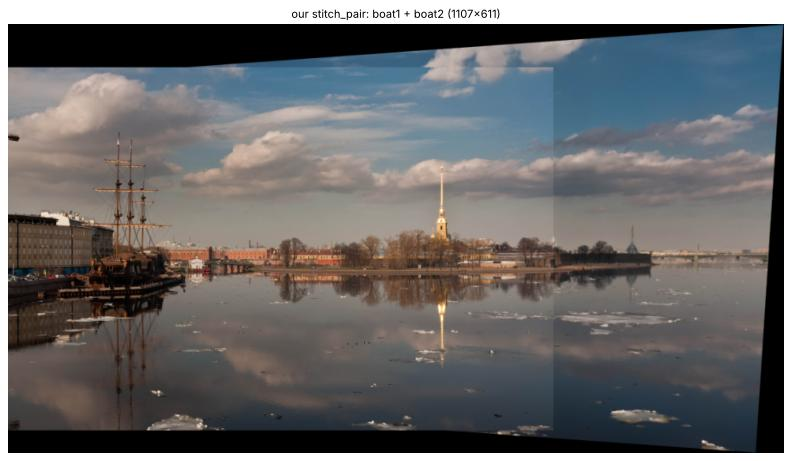

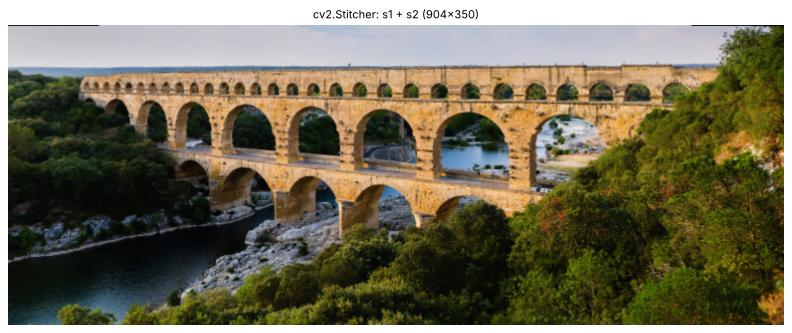

saved output/panorama_s1_s2.jpg


In [15]:
bl, br = load_small("boat1.jpg", 0.2), load_small("boat2.jpg", 0.2)
pano_b, info_b = stitch_pair(bl, br)
print(f"boat pair: good matches {info_b['good']}, inliers {info_b['inliers']} ({100 * info_b['inlier_ratio']:.0f}%)")

t = time.perf_counter()
status, pano_cv = cv2.Stitcher_create(cv2.Stitcher_PANORAMA).stitch([left_img, right_img])
t_cv = time.perf_counter() - t
print("cv2.Stitcher status:", status, "(0 = OK)", f"in {t_cv:.1f}s")
show(pano_b, f"our stitch_pair: boat1 + boat2 ({pano_b.shape[1]}x{pano_b.shape[0]})", size=10)
if status == 0:
    show(pano_cv, f"cv2.Stitcher: s1 + s2 ({pano_cv.shape[1]}x{pano_cv.shape[0]})", size=10)
cv2.imwrite(os.path.join(OUT, "panorama_s1_s2.jpg"), pano)
print("saved", os.path.join(OUT, "panorama_s1_s2.jpg"))

**What to notice:**
- Our fixed `stitch_pair` produces a complete Pont du Gard panorama (left photo intact, right photo warped onto it); 889 of 905 ratio-test matches (98 %) are RANSAC inliers.
- The boat panorama is geometrically right (the spire and the buildings line up), but you can see a **vertical seam**, because the two photos have slightly different exposure, and black **wedges** where the warped right image does not fill the rectangle. Real stitchers fix both with exposure compensation and blending, and crop to the largest inner rectangle.
- `cv2.Stitcher` (0.4 s here) gives a seamless result on s1+s2 thanks to blending. For a lab, our simple version shows the idea; for a product, use `cv2.Stitcher`.

## 9 · 🔧 What we changed from the course notebook, and why

| # | Course code | Problem (verified) | What we did |
|---|---|---|---|
| 1 | `cv2.imread('Ganesh3.jpg')`, `'blackdog.jpg'`, `'left.jpg'`, `'right.jpg'` | The images were never provided. `imread` returns `None` silently and the next line crashes with a confusing `cvtColor` assertion error | Download public OpenCV sample images with a cached `download()` helper; check `img is None` with a clear message |
| 2 | Panorama: `H` maps **left→right**, then `warpPerspective(img1, M, (w+w2, h))` and `result[0:h2, 0:w2] = img2` | With a real left/right pair the left image is warped to **negative x** and cut off, and the part that survives is overwritten by `img2`. The output is just the right photo plus black (also visible in the course's own saved output) | Estimate H **right→left**, compute the bounding box of both images, add a **translation** so nothing is negative, crop black borders |
| 3 | Panorama uses **all** cross-checked matches | Many are wrong; RANSAC hides it. No one looks at the inlier ratio | Lowe ratio test + print inliers / inlier ratio; draw only the inliers |
| 4 | Canvas size `(w + img2.shape[1], h)` | Assumes the images line up horizontally at the same height; anything warped above/below y=0 or below h is cut off | Canvas size computed from the warped corners |
| 5 | Harris: `img[dst > 0.01*dst.max()] = red` | Marks *pixels*, not corners; dots are 1 px wide and nearly invisible on big images | Count corners as connected blobs; dilate the mask for display; show the effect of every parameter |
| 6 | Exercise: "try different images" with no measurement | — | Counted and timed all three detectors on 4 images; ORB also with a fair `nfeatures` |
| 7 | Claims "Harris not scale/rotation invariant…" with no evidence | Partly misleading: Harris *detection* is fairly rotation-stable (see §7); what fails is matching without a scale/orientation-aware descriptor | Measured repeatability and correct-match rate under known rotations and scalings |
| 8 | `plt.imshow` with default figure size | Small, hard-to-see results | Bigger figures, downscaled images (keeps the notebook small) |

## 10 · Results, honestly


- **Harris / SIFT / ORB all work** on the replacement images; the course code for these three cells was correct apart from the missing files.
- **The panorama code in the course notebook is genuinely broken** for a left/right pair: it outputs only the right photo plus black (we reproduced it, and the course's own saved output shows the same thing). The fix is to warp the right image into the left image's frame on a translated canvas.
- **The lecture's invariance claims are confirmed by the matching test**, with one important nuance: Harris *detection* is rotation-stable; Harris fails under rotation only when you match raw patches. Under zoom Harris fails at both detection and matching.
- **"SIFT finds fewer keypoints than ORB" was not true here** with default settings: ORB's default cap of 500 decides the count.
- Timing numbers are from one CPU and vary between runs by roughly ±20 %; the ranking (Harris ≪ ORB ≪ SIFT) is stable.
- Limitations: our simple stitcher pastes without blending, so exposure seams remain; a single homography is only correct for (near-)pure camera rotation or planar scenes.

## 11 · Common errors and how to fix them

| Error / symptom | Cause | Fix |
|---|---|---|
| `error: (-215:Assertion failed) !_src.empty() in function 'cvtColor'` | `cv2.imread` returned `None`: wrong path or file missing (imread never raises) | Check `os.path.exists(path)`; print `os.getcwd()`; test `if img is None` |
| `AttributeError: module 'cv2' has no attribute 'SIFT_create'` | OpenCV older than 4.4 | `pip install -U opencv-python` (or use `cv2.xfeatures2d.SIFT_create()` from `opencv-contrib-python` on old versions) |
| `cornerHarris` assertion about type | Input not `float32`/`uint8` single-channel | `np.float32(gray)` on a **grey** image |
| `des is None` / `bf.match` error "query descriptors empty" | No keypoints found (blank, tiny or very blurry image, or ORB's `edgeThreshold` border bigger than the image) | Check `len(kp)`; use a larger or more textured image; lower `fastThreshold` |
| `bf.match` error about type/size | Mixing descriptor types, e.g. SIFT (float32) with `NORM_HAMMING` | SIFT/SURF → `NORM_L2`; ORB/BRIEF/BRISK → `NORM_HAMMING` |
| `findHomography` returns `None` | Fewer than 4 matches, or all points collinear | Check `len(matches) >= 4`; more features; better overlap |
| Panorama shows only one image / black half | Homography direction vs paste position (§8b) | Map the right image into the left frame, translated canvas |
| Panorama is badly skewed or "folded" | Most matches are wrong (little overlap, repetitive texture) or the scene is not planar and the camera moved | Ratio test, check inlier ratio, take photos by rotating the camera about one spot with 30–50 % overlap |
| Colours look blue/orange-swapped | Showing a BGR image with matplotlib | `cv2.cvtColor(img, cv2.COLOR_BGR2RGB)` |

## 12 · Try this yourself

1. Take two photos of your room with your phone, rotating (not walking) about 20° between them, with about 40 % overlap. Stitch them with `stitch_pair`. Then try **walking** sideways between shots; why is the result worse? (Hint: parallax; a single homography only fits a plane or a pure rotation.)
2. In §7, add a **blur** or **brightness** change (`cv2.GaussianBlur`, `cv2.convertScaleAbs(g, alpha=1.5)`) instead of rotation. Which detector is most robust?
3. Replace ORB by SIFT in `stitch_pair` (remember `NORM_L2`). Compare the inlier count and run time.
4. Run Harris with `cv2.goodFeaturesToTrack(gray, 100, 0.01, 10, useHarrisDetector=True)`: you get a clean list of 100 corners with non-maximum suppression built in.
5. Stitch three images (`boat1`, `boat2`, `boat3`) by stitching the first two, then stitching the result with the third. What goes wrong as the panorama grows?
6. Add simple blending: in the overlap, average the two images (or use a linear "feather" weight) and compare the seam.

## 13 · Viva questions (with short model answers)

1. **What is a feature/keypoint, and what makes a good one?** A distinctive, repeatable point (corner/blob) that can be found again in another image of the same scene; good = distinctive, repeatable under viewpoint/scale/lighting change, well localised.
2. **Detector vs descriptor?** Detector finds *where* (x, y, scale, angle); descriptor encodes *what the neighbourhood looks like* as a vector so points can be compared. Harris is only a detector; SIFT/ORB are both.
3. **Why are corners better than edges?** At a corner the image changes in every direction, so the position is unique; along an edge it looks the same, so you can't tell where you are (the *aperture problem*).
4. **Explain the Harris response.** Build the 2×2 structure tensor M from gradients in a window; R = det(M) − k·trace(M)² = λ1λ2 − k(λ1+λ2)². R ≫ 0 corner, R < 0 edge, |R| small flat.
5. **What do `blockSize`, `ksize` and `k` in `cornerHarris(gray, 2, 3, 0.04)` mean?** Window size for M (2), Sobel aperture for gradients (3), the empirical constant k (0.04–0.06; higher → fewer corners).
6. **Why `dst > 0.01*dst.max()`?** It keeps pixels whose response is at least 1 % of the strongest; it is a *relative* threshold, so lower → more corners. It marks pixels, not individual corners.
7. **Is Harris rotation invariant?** The corner *response* uses eigenvalues, which do not change when the image rotates, so detection is largely rotation-stable (we measured this). But Harris has no orientation or scale, so a raw-patch comparison fails under rotation, and corners appear/disappear when the image is zoomed: it is **not scale invariant**.
8. **How does SIFT achieve scale and rotation invariance?** Scale: searches for DoG extrema across a Gaussian scale space and assigns each keypoint a characteristic scale. Rotation: assigns a dominant gradient orientation and computes the descriptor relative to it.
9. **What is in a SIFT descriptor?** 16×16 region → 4×4 cells × 8-bin orientation histograms = 128 floats, normalised (illumination robustness).
10. **What does ORB stand for and why is it fast?** Oriented FAST and Rotated BRIEF: FAST corners (simple pixel-ring test), BRIEF binary descriptor (256 intensity comparisons, 32 bytes) compared with Hamming distance (XOR + bit count).
11. **Why does `ORB_create()` always give 500 keypoints?** `nfeatures=500` is the default cap; change it with `ORB_create(nfeatures=N)`.
12. **ORB vs SIFT?** ORB: free, ~10× faster, binary, rotation invariant, limited scale range (8-level pyramid). SIFT: slower, float descriptors, more robust to large scale changes (our test: correct matches stay ≈ 95 % at 3× zoom, ORB ≈ 50 %).
13. **What is a homography and when is it valid for stitching?** A 3×3 projective transform (8 DOF) between two image planes; valid for a planar scene or a camera rotating about its optical centre. Needs ≥ 4 point pairs.
14. **What does RANSAC do and what is the 5.0 in `findHomography(..., cv2.RANSAC, 5.0)`?** Repeatedly fits H to 4 random matches and keeps the H with most inliers; 5.0 is the reprojection threshold in pixels for a match to count as an inlier.
15. **What was wrong with the course panorama code?** H mapped the left image into the right image's frame, where it lies at negative x and is clipped; the remainder is overwritten by pasting img2. Fix: warp the right image into the left frame (or translate the canvas).
16. **What is `crossCheck=True`?** Keep match i↔j only if j is i's best match *and* i is j's best match; removes many one-sided wrong matches. Cannot be combined with `knnMatch` ratio test (k=2).